# Modelo 1 · Próximo movimiento de la competencia
## Notebook 3 · Parte 2: clasificar ¿bajará el precio?

**La pregunta.** Para cada producto en cada comercio y cada día: *¿bajará su precio al menos 5 % frente al de hoy?* Es una **clasificación binaria**: clase 1 si baja, clase 0 si no.

| Tarea | Etiqueta | Horizonte | Para qué sirve |
|---|---|---|---|
| **A** | `baja_7d` | en algún día de los **próximos 7** | lista semanal de productos a vigilar |
| **B** | `baja_1d` | **mañana** | la fecha exacta, para preparar el precio a tiempo |

**La tabla lista.** `datos/tabla_clasificacion.parquet` trae una fila por serie y día (una de cada 7 fechas), las 23 variables del baseline (calculadas solo con información hasta ese día) y las dos etiquetas. Es una tabla `X, y` como las de clase.

**Métricas.** Las clases están **desbalanceadas** (≈8 % de 1 en A y ≈1 % en B): un modelo que diga "nunca baja" acierta 92 % y no sirve. Por eso la métrica principal es la **AP** (área bajo la curva precision–recall) y, para el negocio, los **aciertos por cada 100 alertas** (el 5 % de mayor riesgo).

**Cortes por fecha** (nunca al azar): entrenamiento 2023–2024 · validación ene–jun 2025 · prueba jul–dic 2025 (la guarda Pycca).

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.dates as mdates
warnings.filterwarnings('ignore')
RAIZ = Path('..') if Path('../variables.py').exists() else Path('.')     # repo (notebooks/) o paquete de ESPOL
sys.path.insert(0, str(RAIZ)); sys.path.insert(0, '.')
import estilo; estilo.aplicar()
from estilo import AZUL, NARANJA, AQUA, TINTA2, GRIS, pie
DATOS = RAIZ / 'datos'
pd.set_option('display.width', 160)
import variables as V
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, classification_report, confusion_matrix, precision_recall_curve, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

### 1. La tabla: filas, variables y etiquetas

In [2]:
tabla = pd.read_parquet(DATOS / 'tabla_clasificacion.parquet')
print(f'{len(tabla):,} filas | {len(V.COLUMNAS)} variables:', ', '.join(V.COLUMNAS))
tabla.head()

459,611 filas | 23 variables: comercio_cod, division_cod, tachado, desc_actual, en_oferta_hoy, cambio_1d, cambio_7d, cambio_30d, vs_max_30d, vs_min_90d, dias_sin_cambio, ofertas_90d, inicios_oferta_365d, bajas_prod_7d, bajas_otros_7d, vs_mediana_comercios, n_comercios, evento_activo, dias_a_evento, dias_a_black_friday, dia_semana, dia_mes, mes


,fecha,corte,comercio_id,producto_id,comercio_cod,division_cod,tachado,desc_actual,en_oferta_hoy,cambio_1d,...,vs_mediana_comercios,n_comercios,evento_activo,dias_a_evento,dias_a_black_friday,dia_semana,dia_mes,mes,baja_7d,baja_1d
0,2023-01-01,entrenamiento,C01,P00003,0,8,0,0.0,0.0,NaN,...,-0.002874,2,0,73.0,327,6,1,1,0.0,0.0
1,2023-01-08,entrenamiento,C01,P00003,0,8,0,0.0,0.0,0.0,...,-0.002874,2,0,66.0,320,6,8,1,0.0,0.0
2,2023-01-15,entrenamiento,C01,P00003,0,8,0,0.0,0.0,0.0,...,-0.002874,2,0,59.0,313,6,15,1,0.0,0.0
3,2023-01-22,entrenamiento,C01,P00003,0,8,0,0.0,0.0,0.0,...,-0.002874,2,0,52.0,306,6,22,1,0.0,0.0
4,2023-01-29,entrenamiento,C01,P00003,0,8,0,0.0,0.0,0.0,...,-0.002874,2,0,45.0,299,6,29,1,0.0,0.0


In [3]:
EVAL = [k for k in ('validacion', 'prueba') if (tabla.corte == k).any()]
pd.DataFrame({k: {'filas': len(x), '% de 1 · tarea A': round(100 * x.baja_7d.mean(), 2), '% de 1 · tarea B': round(100 * x.baja_1d.mean(), 2)}
              for k, x in tabla.groupby('corte', sort=False)}).T

,filas,% de 1 · tarea A,% de 1 · tarea B
entrenamiento,370054.0,7.75,1.26
validacion,89557.0,7.28,1.24


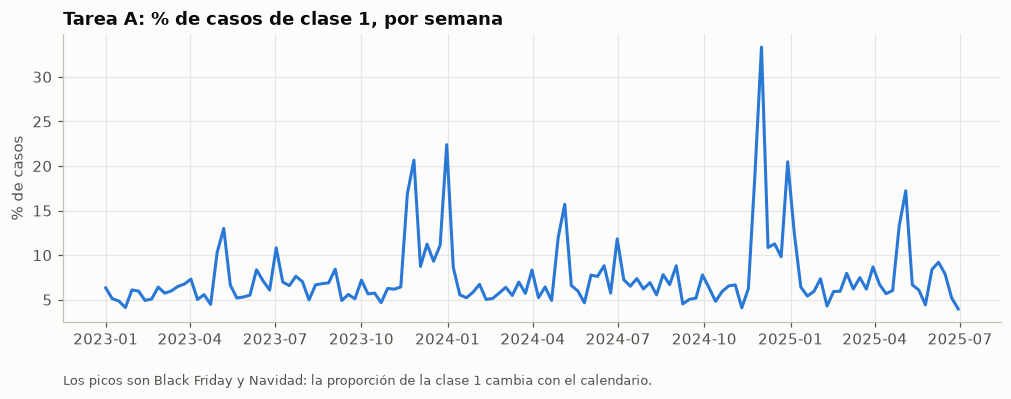

In [4]:
s = tabla.groupby(pd.Grouper(key='fecha', freq='W')).baja_7d.mean() * 100
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(s.index, s.values, color=AZUL)
ax.set_title('Tarea A: % de casos de clase 1, por semana'); ax.set_ylabel('% de casos')
pie(ax, 'Los picos son Black Friday y Navidad: la proporción de la clase 1 cambia con el calendario.')
plt.show()

### 2. Cuatro modelos, de lo más simple a lo más potente

- **Regla:** la tasa histórica de bajas de cada comercio en cada mes (lo que haría una tabla dinámica).
- **Regresión logística:** las categorías (`comercio_cod`, `division_cod`) en variables indicadoras y las numéricas estandarizadas.
- **Árbol de decisión:** profundidad 6, fácil de leer.
- **Baseline (boosting de árboles):** `HistGradientBoostingClassifier`, el modelo a superar.

In [5]:
NUM = [c for c in V.COLUMNAS if c not in V.CATEGORICAS]

def modelos(extra=()):
    cols = V.COLUMNAS + list(extra)
    cat = V.CATEGORICAS + list(extra)
    prep = ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), cat),
                              ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), [c for c in cols if c not in cat])])
    return cols, {'regresión logística': make_pipeline(prep, LogisticRegression(max_iter=1000)),
                  'árbol de decisión': make_pipeline(SimpleImputer(strategy='median'), DecisionTreeClassifier(max_depth=6, min_samples_leaf=500, random_state=7)),
                  'baseline (boosting)': HistGradientBoostingClassifier(max_iter=400, learning_rate=0.06, max_leaf_nodes=63, min_samples_leaf=200,
                                                                        l2_regularization=1.0, categorical_features=[cols.index(c) for c in cat], random_state=7)}

def top(y, p, q=0.05):
    n = max(1, int(len(p) * q)); return float(np.asarray(y)[np.argsort(-np.asarray(p))[:n]].mean())

def entrenar(y, extra=(), solo=None, datos=None):
    datos = tabla if datos is None else datos
    tr = datos[datos.corte == 'entrenamiento'].dropna(subset=[y])
    cols, ms = modelos(extra)
    if solo:
        ms = {k: v for k, v in ms.items() if k in solo}
    for m in ms.values():
        m.fit(tr[cols], tr[y].astype(int))
    tasa = tr.groupby(['comercio_id', 'mes'])[y].mean(); glob = tr[y].mean()
    pred, filas = {}, []
    for k in EVAL:
        x = datos[datos.corte == k].dropna(subset=[y]).copy()
        if not solo:
            x['regla'] = pd.Series(list(zip(x.comercio_id, x.mes)), index=x.index).map(tasa).fillna(glob).values
        for n, m in ms.items():
            x[n] = m.predict_proba(x[cols])[:, 1]
        pred[k] = x
        for n in [c for c in ('regla', *ms) if c in x]:
            filas.append({'corte': k, 'modelo': n, 'AP': average_precision_score(x[y], x[n]), 'AUC': roc_auc_score(x[y], x[n]),
                          'aciertos por 100 alertas': 100 * top(x[y], x[n]), 'azar (% de 1)': 100 * x[y].mean()})
    return ms, pred, pd.DataFrame(filas).round(3)

mA, pA, rA = entrenar('baja_7d')
rA

,corte,modelo,AP,AUC,aciertos por 100 alertas,azar (% de 1)
0,validacion,regla,0.125,0.643,18.696,7.276
1,validacion,regresión logística,0.275,0.770,36.029,7.276
2,validacion,árbol de decisión,0.252,0.767,36.297,7.276
3,validacion,baseline (boosting),0.365,0.808,45.209,7.276


### 3. Curva precision–recall (tarea A)

Cuanto más arriba y a la derecha, mejor. La AP es el área bajo la curva; la línea punteada es el azar.

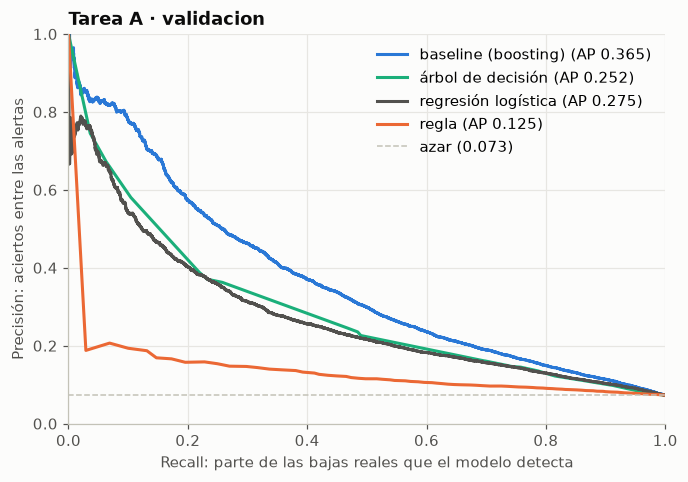

In [6]:
k = EVAL[-1]; x = pA[k]
fig, ax = plt.subplots(figsize=(7, 4.6))
for mod, col in zip(('baseline (boosting)', 'árbol de decisión', 'regresión logística', 'regla'), (AZUL, AQUA, TINTA2, NARANJA)):
    pr, rc, _ = precision_recall_curve(x.baja_7d, x[mod])
    ax.plot(rc, pr, color=col, label=f'{mod} (AP {average_precision_score(x.baja_7d, x[mod]):.3f})')
ax.axhline(x.baja_7d.mean(), color=GRIS, ls='--', lw=1, label=f'azar ({x.baja_7d.mean():.3f})')
ax.set_xlabel('Recall: parte de las bajas reales que el modelo detecta'); ax.set_ylabel('Precisión: aciertos entre las alertas')
ax.set_title(f'Tarea A · {k}'); ax.legend(); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
plt.show()

### 4. Matriz de confusión

El modelo da una probabilidad; para decidir "alerta sí o no" hace falta un **umbral**. Aquí se marca como alerta el 5 % de mayor riesgo (lo que un analista alcanza a revisar) y se cuenta cuántas alertas aciertan.

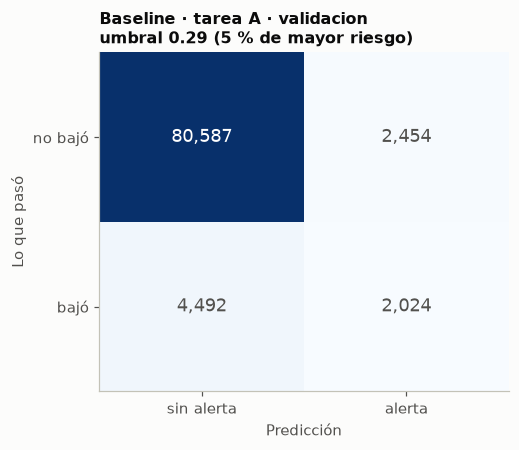

              precision    recall  f1-score   support

     no bajó      0.947     0.970     0.959     83041
        bajó      0.452     0.311     0.368      6516

    accuracy                          0.922     89557
   macro avg      0.700     0.641     0.663     89557
weighted avg      0.911     0.922     0.916     89557



In [7]:
p = x['baseline (boosting)']; umbral = np.quantile(p, 0.95)
alerta = (p >= umbral).astype(int)
cm = confusion_matrix(x.baja_7d.astype(int), alerta)
fig, ax = plt.subplots(figsize=(4.8, 4))
ax.imshow(cm, cmap='Blues', aspect='auto'); ax.grid(False)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f'{cm[i, j]:,}', ha='center', va='center', fontsize=12, color='white' if cm[i, j] > cm.max() * 0.6 else TINTA2)
ax.set_xticks([0, 1], ['sin alerta', 'alerta']); ax.set_yticks([0, 1], ['no bajó', 'bajó'])
ax.set_xlabel('Predicción'); ax.set_ylabel('Lo que pasó'); ax.set_title(f'Baseline · tarea A · {k}\numbral {umbral:.2f} (5 % de mayor riesgo)', fontsize=10.5)
plt.show()
print(classification_report(x.baja_7d.astype(int), alerta, target_names=['no bajó', 'bajó'], digits=3))

### 5. ¿En qué se fija el baseline?

Caída de la AP al desordenar cada variable (si cae mucho, la variable importa).

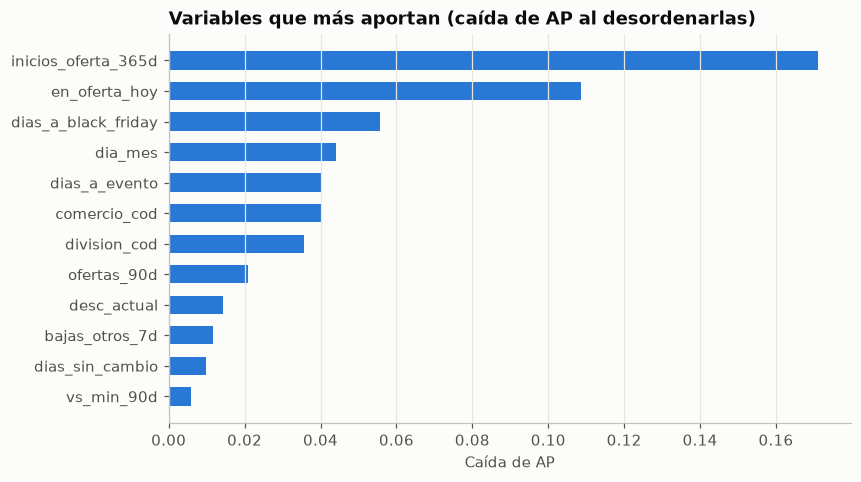

In [8]:
smp = pA[EVAL[-1]].sample(min(60000, len(pA[EVAL[-1]])), random_state=7)
mb = mA['baseline (boosting)']
base = average_precision_score(smp.baja_7d, mb.predict_proba(smp[V.COLUMNAS])[:, 1]); rng = np.random.default_rng(7); imp = {}
for c in V.COLUMNAS:
    z = smp[V.COLUMNAS].copy(); z[c] = rng.permutation(z[c].values)
    imp[c] = base - average_precision_score(smp.baja_7d, mb.predict_proba(z)[:, 1])
imp = pd.Series(imp).sort_values().tail(12)
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(imp.index, imp.values, color=AZUL, height=0.6); ax.grid(axis='y', visible=False)
ax.set_title('Variables que más aportan (caída de AP al desordenarlas)'); ax.set_xlabel('Caída de AP')
plt.show()

### 6. Uniendo las dos partes: el grupo como variable

Se agrega el grupo de cada serie (de `grupos_baseline.csv`, el notebook 2) como una variable categórica más del baseline. Los grupos se calcularon con el entrenamiento, así que no miran el futuro.

In [9]:
g = pd.read_csv(RAIZ / 'grupos_baseline.csv')
tg = tabla.merge(g, on=['comercio_id', 'producto_id'], how='left')
tg['grupo'] = tg.grupo.fillna(-1).astype(int)
_, _, rG = entrenar('baja_7d', extra=['grupo'], solo=['baseline (boosting)'], datos=tg)
pd.concat([rA[rA.modelo == 'baseline (boosting)'].assign(variables='23 variables'),
           rG.assign(variables='23 variables + grupo del baseline de clustering')])[['corte', 'variables', 'AP', 'AUC', 'aciertos por 100 alertas']]

,corte,variables,AP,AUC,aciertos por 100 alertas
3,validacion,23 variables,0.365,0.808,45.209
0,validacion,23 variables + grupo del baseline de clustering,0.368,0.810,45.254


Con los grupos del baseline de clustering la ganancia es mínima: esos grupos casi repiten lo que el comercio ya dice. **Un mejor agrupamiento (parte 1) debería notarse aquí.**

### 7. Tarea B: ¿baja mañana?

Más difícil (≈1 % de casos), pero es la que dice **la fecha**.

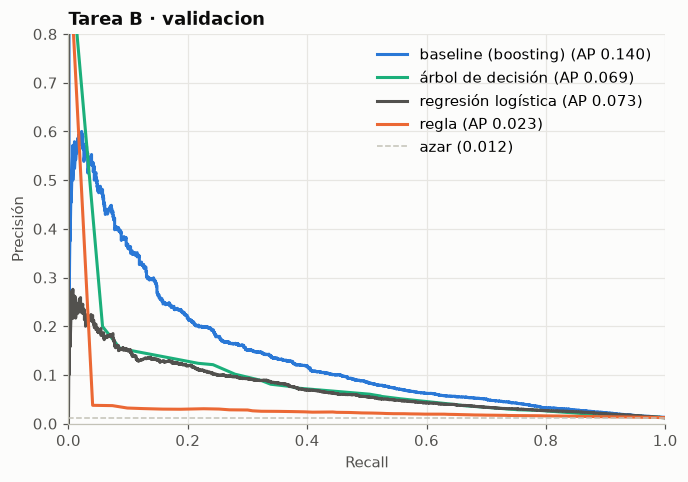

,corte,modelo,AP,AUC,aciertos por 100 alertas,azar (% de 1)
0,validacion,regla,0.023,0.652,3.099,1.237
1,validacion,regresión logística,0.073,0.800,8.453,1.237
2,validacion,árbol de decisión,0.069,0.791,8.271,1.237
3,validacion,baseline (boosting),0.140,0.837,10.504,1.237


In [10]:
mB, pB, rB = entrenar('baja_1d')
xb = pB[EVAL[-1]]
fig, ax = plt.subplots(figsize=(7, 4.6))
for mod, col in zip(('baseline (boosting)', 'árbol de decisión', 'regresión logística', 'regla'), (AZUL, AQUA, TINTA2, NARANJA)):
    pr, rc, _ = precision_recall_curve(xb.baja_1d, xb[mod])
    ax.plot(rc, pr, color=col, label=f'{mod} (AP {average_precision_score(xb.baja_1d, xb[mod]):.3f})')
ax.axhline(xb.baja_1d.mean(), color=GRIS, ls='--', lw=1, label=f'azar ({xb.baja_1d.mean():.3f})')
ax.set_xlabel('Recall'); ax.set_ylabel('Precisión'); ax.set_title(f'Tarea B · {EVAL[-1]}'); ax.legend(); ax.set_xlim(0, 1); ax.set_ylim(0, 0.8)
plt.show()
rB

## Resumen

- **Métrica a seguir: AP** (para elegir modelos) y **aciertos por cada 100 alertas** (para el negocio).
- El boosting supera a la regla, a la regresión logística y al árbol en las dos tareas. Las cifras oficiales del baseline salen de `baseline.py`, que usa todos los días (esta tabla trae uno de cada 7); son muy parecidas.
- **Dónde mejorar:** la tarea B (la fecha exacta) y usar bien los grupos de la parte 1. Pistas: rezago entre comercios ("¿cuántos días hace que bajó otro?"), duración típica de las ofertas de cada comercio, calendario **por división**, precio frente al comercio más barato y el tipo de serie.